# MMA3001 — Stage 2: FD001 Data Preprocessing

**Project:** Predicting Remaining Useful Life (RUL) of Turbofan Engines Using Machine Learning  
**Dataset:** NASA C-MAPSS **FD001 only**  
**Goal:** Produce reproducible, properly separated datasets that can be used for Linear Regression, Random Forest Regression and Neural Network Regression in Stage 3.

The **test RUL labels are never opened in this notebook**. Test engine trajectories are not run-to-failure, so their last recorded cycle **is not a failure cycle**.

**Model inputs:** `cycle` and 14 nonconstant, non-near-constant sensor channels. `engine_id` is a *grouping key only*. Operational settings are excluded because FD001 represents a single operating regime and its setting variations are tiny; this is a documented initial modelling assumption, not an assertion that these settings are universally irrelevant. Final input selection can be checked by validation ablation in Stage 3.

## 1 — Load files, check data integrity and construct training RUL

For a training engine, `RUL = maximum recorded cycle − current cycle`. We use **uncapped** RUL because it is directly defined by the dataset. Engine IDs identify distinct histories and must not be used as predictive features.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

BASE = Path.cwd()
if not (BASE/'data'/'train_FD001.txt').exists():
    BASE = BASE/'MMA3001_FD001_Stage2'
assert (BASE/'data'/'train_FD001.txt').is_file(), f'Cannot locate data in {BASE}'
DATA, OUT, FIG = (BASE / x for x in ('data','processed','figures'))
OUT.mkdir(exist_ok=True, parents=True)
FIG.mkdir(exist_ok=True, parents=True)

COLS = ['engine_id','cycle'] + [f'setting_{k}' for k in range(1,4)] + [f'sensor_{k}' for k in range(1,22)]
SENSOR_COLS = [f'sensor_{k}' for k in range(1,22)]
train = pd.read_csv(DATA/'train_FD001.txt', sep=r'\s+', names=COLS, header=None)
test  = pd.read_csv(DATA/'test_FD001.txt',  sep=r'\s+', names=COLS, header=None)

assert train.shape == (20631,26), f'Unexpected train shape {train.shape}'
assert test.shape == (13096,26), f'Unexpected test shape {test.shape}'
assert not train.isna().any().any() and not test.isna().any().any()
assert not train.duplicated(['engine_id','cycle']).any()
assert not test.duplicated(['engine_id','cycle']).any()
assert train.engine_id.nunique() == test.engine_id.nunique() == 100
for df in (train,test):
    assert all(np.array_equal(group.cycle.to_numpy(), np.arange(1,len(group)+1))
               for _, group in df.groupby('engine_id'))

failure_cycle = train.groupby('engine_id').cycle.max()
train['RUL'] = train.engine_id.map(failure_cycle) - train.cycle
assert (train.RUL >= 0).all()
assert (train.groupby('engine_id').RUL.min() == 0).all()
print('Original training:', train.shape, '| test:', test.shape)
print('RUL range (training):',train.RUL.min(),train.RUL.max())
print(train[['engine_id','cycle','sensor_4','sensor_11','RUL']].head(5).to_string(index=False))

Original training: (20631, 27) | test: (13096, 26)
RUL range (training): 0 361
 engine_id  cycle  sensor_4  sensor_11  RUL
         1      1   1400.60      47.47  191
         1      2   1403.14      47.49  190
         1      3   1404.20      47.27  189
         1      4   1401.87      47.13  188
         1      5   1406.22      47.28  187


## 2 — Split by entire engine (80 train / 20 validation)

A random row split would put different cycles from **the same engine** in both subsets, producing overly optimistic results. We use `GroupShuffleSplit` with a fixed random seed, preserving complete engine trajectories in one subset. We will only examine training-fold statistics when selecting features and fitting scalers.

Training subset: 16,561 rows, 80 engines
Validation subset: 4,070 rows, 20 engines
Validation engine IDs: [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


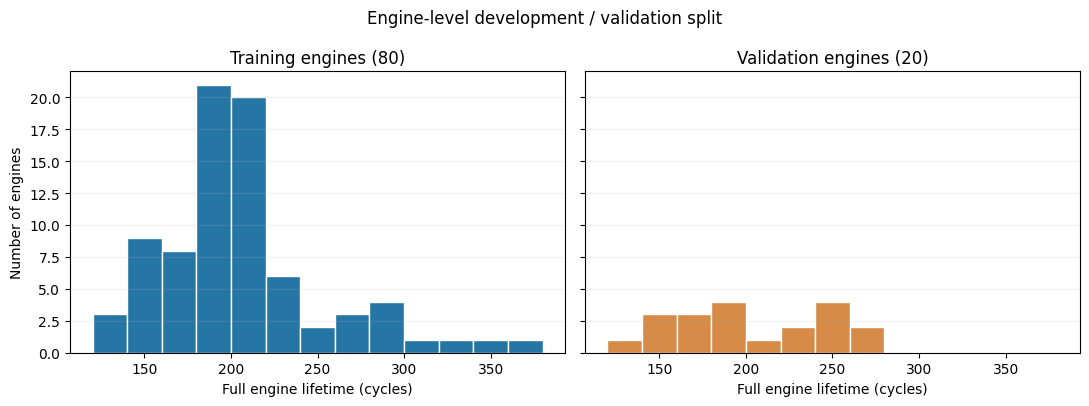

In [2]:
SPLIT_SEED = 42
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SPLIT_SEED)
indices_train, indices_val = next(splitter.split(train, groups=train.engine_id))
development = train.iloc[indices_train].copy().sort_values(['engine_id','cycle']).reset_index(drop=True)
validation = train.iloc[indices_val].copy().sort_values(['engine_id','cycle']).reset_index(drop=True)
ids_train = sorted(development.engine_id.unique().astype(int).tolist())
ids_val = sorted(validation.engine_id.unique().astype(int).tolist())
assert len(ids_train) == 80 and len(ids_val) == 20
assert not (set(ids_train)&set(ids_val))
assert len(development)+len(validation) == len(train)
assert len(set(zip(train.engine_id,train.cycle))) == len(train)
print(f'Training subset: {len(development):,} rows, {len(ids_train)} engines')
print(f'Validation subset: {len(validation):,} rows, {len(ids_val)} engines')
print('Validation engine IDs:', ids_val)

fig, axs = plt.subplots(1,2,figsize=(11,4.1),sharey=True)
for ax, df, ttl, colour in [(axs[0],development,'Training engines (80)','#2676a5'),
                             (axs[1],validation,'Validation engines (20)','#d78b48')]:
    lifetimes = df.groupby('engine_id').cycle.max()
    ax.hist(lifetimes,bins=np.arange(120,381,20),color=colour,edgecolor='white')
    ax.set(xlabel='Full engine lifetime (cycles)',title=ttl)
    ax.grid(axis='y',alpha=.18)
axs[0].set_ylabel('Number of engines')
fig.suptitle('Engine-level development / validation split')
fig.tight_layout()
fig.savefig(FIG/'01_engine_level_split.png',dpi=180)
plt.show()

## 3 — Initial feature selection without leakage

A sensor is initially excluded if it has **at most two distinct values in the 80-engine training fold**. This reproducible rule removes the six exactly constant channels and near-constant S6; the tiny variations in S6 are not useful for our simple initial baseline. We retain all other sensors, including channels with weak individual linear correlations, because nonlinear models may exploit their interactions.

We include `cycle` because elapsed usage is meaningful, but Stage 3 **must** compare against a cycle-only baseline to demonstrate incremental information from sensor channels. We exclude `engine_id` as a predictive feature, and exclude the three operating settings as a first-pass engineering assumption for FD001.

In [3]:
distinct_counts = development[SENSOR_COLS].nunique()
EXCLUDED_SENSORS = distinct_counts[distinct_counts <= 2].index.tolist()
SELECTED_SENSORS = [sensor for sensor in SENSOR_COLS if sensor not in EXCLUDED_SENSORS]
FEATURES = ['cycle'] + SELECTED_SENSORS
CYCLE_ONLY = ['cycle']
assert len(EXCLUDED_SENSORS) == 7, EXCLUDED_SENSORS
assert len(SELECTED_SENSORS) == 14, SELECTED_SENSORS
assert len(FEATURES) == 15
assert all(test[col].notna().all() for col in FEATURES)
print('Excluded sensors:', EXCLUDED_SENSORS)
print('Selected sensors:', SELECTED_SENSORS)
print('Total model features:', len(FEATURES), '(cycle + 14 sensors)')
print('Operational settings excluded: setting_1, setting_2, setting_3')
print('Engine ID reserved for grouping only, not a model feature')

Excluded sensors: ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Selected sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Total model features: 15 (cycle + 14 sensors)
Operational settings excluded: setting_1, setting_2, setting_3
Engine ID reserved for grouping only, not a model feature


## 4 — Construct simulated partial histories for validation

NASA's official FD001 test engines are **truncated before failure**, so their labels describe how many cycles remain **at the final supplied observation**. For a more comparable validation metric, select **one artificial stop point for each held-out validation engine**, without using its future sensor values in the corresponding prediction row.

The known complete validation history is used **only to calculate the correct RUL label and to establish a pre-failure cutoff**. The cutoff is chosen reproducibly between 30% and 90% of the full observed life; this is an *illustrative simulation of censoring*, not a claim that NASA uses the same cutoff distribution. We retain the full validation histories for diagnostics but tune models based on the 20 independent validation snapshots. The modest sample size is an explicit limitation.

Validation snapshots (one per held-out engine):
 engine_id  cycle  RUL
         1     78  114
         5    183   86
        11    139  101
        13     85   78
        19     81   77
        23    130   38
        31    197   37
        32     77  114
        34    134   61
        40     90   98
        45    139   19
        46    218   38
        54    175   82
        71    156   52
        74    101   65
        77    122   32
        78    131  100
        81    120  120
        84    124  143
        91     58   77


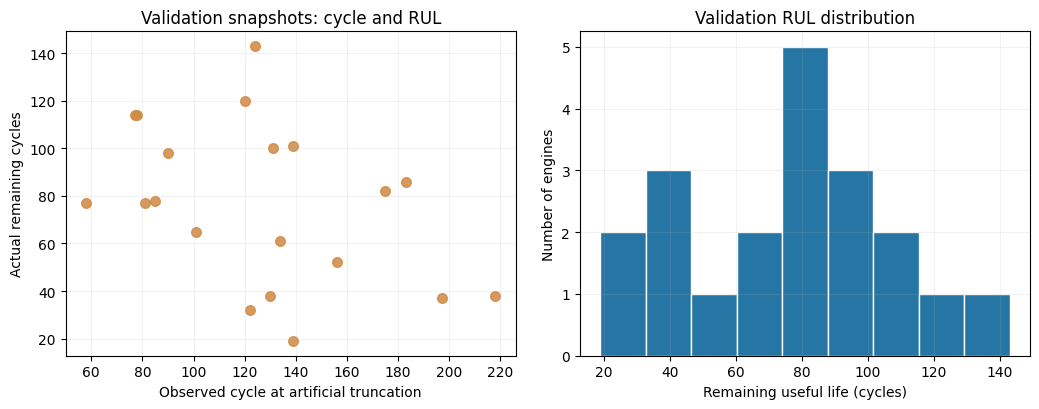

In [4]:
CENSOR_SEED = 2026
rng = np.random.default_rng(CENSOR_SEED)
snapshot_records = []
cutoff_fractions = {}
for engine_id, grp in validation.groupby('engine_id'):
    life = int(grp.cycle.max())
    frac = float(rng.uniform(.30,.90))
    cutoff = max(1,min(life-1, int(np.floor(frac*life))))
    rec = grp.loc[grp.cycle.eq(cutoff)].iloc[0].copy()
    snapshot_records.append(rec)
    cutoff_fractions[int(engine_id)] = frac
snapshots = pd.DataFrame(snapshot_records).sort_values('engine_id').reset_index(drop=True)
snapshots[['engine_id','cycle','RUL']] = snapshots[['engine_id','cycle','RUL']].astype(int)
assert len(snapshots) == 20 and snapshots.engine_id.nunique() == 20
assert (snapshots.RUL > 0).all()
assert (snapshots.cycle < snapshots.engine_id.map(validation.groupby('engine_id').cycle.max())).all()
print('Validation snapshots (one per held-out engine):')
print(snapshots[['engine_id','cycle','RUL']].to_string(index=False))

fig, axs = plt.subplots(1,2,figsize=(10.5,4.2))
axs[0].scatter(snapshots.cycle,snapshots.RUL,c='#d18a43',s=48,alpha=.86)
axs[0].set(xlabel='Observed cycle at artificial truncation',ylabel='Actual remaining cycles',title='Validation snapshots: cycle and RUL')
axs[1].hist(snapshots.RUL,bins=9,color='#2676a5',edgecolor='white')
axs[1].set(xlabel='Remaining useful life (cycles)',ylabel='Number of engines',title='Validation RUL distribution')
for ax in axs: ax.grid(alpha=.16)
fig.tight_layout()
fig.savefig(FIG/'02_validation_snapshots.png',dpi=180)
plt.show()

## 5 — Prepare test inputs, and fit the scaler ONLY on the 80 training engines

The official **test end point** for each engine is its last recorded observation. Importantly, the `RUL_FD001.txt` file is not loaded here or included in any prediction feature. At Stage 4, the selected model and any preprocessing should be **refitted on all 100 original training engines**, then applied to these test endpoint features.

We fit a `StandardScaler` on the 80-engine training split only. This scaler is appropriate for Linear Regression and the Neural Network; Random Forest can use raw numerical inputs. Its purpose here is **development and validation**, not necessarily the final retrained model.

TRAIN X raw/scaled: (16561, 15) (16561, 15)
VALIDATION snapshots X raw/scaled: (20, 15) (20, 15)
HELD-OUT NASA test endpoints X raw: (100, 15)
Scaler fitted on training-fold rows: 16561
Test labels accessed: NO


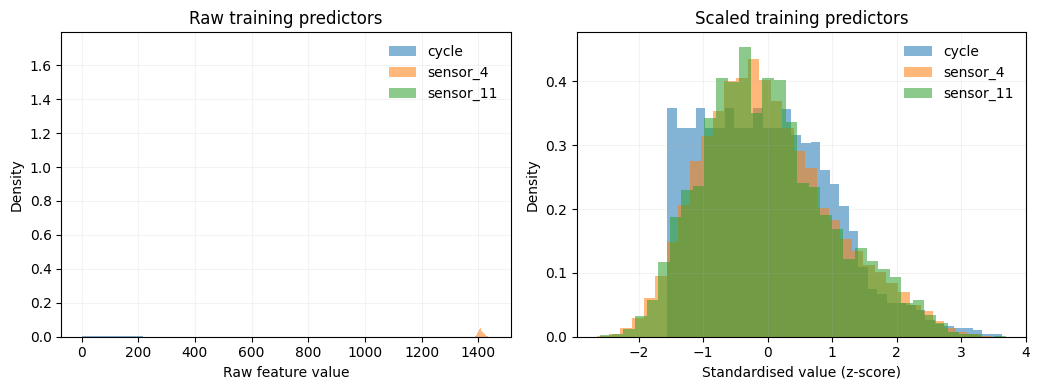

In [5]:
test_endpoints = (test.sort_values(['engine_id','cycle'])
                  .groupby('engine_id',as_index=False).tail(1)
                  .sort_values('engine_id').reset_index(drop=True))
assert test_endpoints.engine_id.nunique() == 100 and len(test_endpoints) == 100
assert 'RUL' not in test_endpoints.columns

X_train = development[FEATURES].to_numpy(dtype=np.float64)
X_val_all = validation[FEATURES].to_numpy(dtype=np.float64)
X_val = snapshots[FEATURES].to_numpy(dtype=np.float64)
X_test_end = test_endpoints[FEATURES].to_numpy(dtype=np.float64)
y_train = development.RUL.to_numpy(dtype=np.float64)
y_val_all = validation.RUL.to_numpy(dtype=np.float64)
y_val = snapshots.RUL.to_numpy(dtype=np.float64)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_val_all_scaled = scaler.transform(X_val_all)
# This transform is for inspection only; final test preprocessing gets refit in Stage 4.
X_test_end_scaled_preview = scaler.transform(X_test_end)
assert np.isfinite(X_train_scaled).all() and np.isfinite(X_val_scaled).all()
assert (np.abs(X_train_scaled.mean(axis=0)) < 1e-10).all()
joblib.dump(scaler, OUT/'scaler_development_80_engines.joblib')

print('TRAIN X raw/scaled:', X_train.shape, X_train_scaled.shape)
print('VALIDATION snapshots X raw/scaled:', X_val.shape, X_val_scaled.shape)
print('HELD-OUT NASA test endpoints X raw:', X_test_end.shape)
print('Scaler fitted on training-fold rows:',int(scaler.n_samples_seen_))
print('Test labels accessed: NO')

sample_cols = ['cycle','sensor_4','sensor_11']
fig,axs = plt.subplots(1,2,figsize=(10.5,4))
for name in sample_cols:
    j=FEATURES.index(name)
    axs[0].hist(X_train[:,j],bins=35,alpha=.55,label=name,density=True)
    axs[1].hist(X_train_scaled[:,j],bins=35,alpha=.55,label=name,density=True)
axs[0].set(title='Raw training predictors',xlabel='Raw feature value',ylabel='Density')
axs[1].set(title='Scaled training predictors',xlabel='Standardised value (z-score)',ylabel='Density')
for ax in axs:
    ax.legend(frameon=False)
    ax.grid(alpha=.15)
fig.tight_layout()
fig.savefig(FIG/'03_training_feature_standardisation.png',dpi=180)
plt.show()

## 6 — Save data products and reproducibility metadata

The saved outputs contain **only the specified feature list**, engine identifier and, where available, target `RUL`. They do **not** include any future sensor values as predictive features. The whole-engine ID lists, feature ordering, seeds and exclusion rules are saved in `feature_manifest.json`.

Stage 3 can load the `.npz` arrays directly. For convenience, individual CSV files are also provided. The NASA official test labels remain sealed in the raw data folder and must be used only for final evaluation.

In [6]:
train_cols = ['engine_id'] + FEATURES + ['RUL']
test_cols = ['engine_id'] + FEATURES
development[train_cols].to_csv(OUT/'train_engine_rows.csv',index=False)
validation[train_cols].to_csv(OUT/'validation_engine_rows.csv',index=False)
snapshots[train_cols].to_csv(OUT/'validation_snapshots.csv',index=False)
test_endpoints[test_cols].to_csv(OUT/'test_last_observations_NO_LABELS.csv',index=False)

np.savez_compressed(OUT/'stage2_model_arrays.npz',
   feature_names=np.array(FEATURES),
   X_train_raw=X_train, X_train_scaled=X_train_scaled, y_train=y_train,
   train_engine_ids=development.engine_id.to_numpy(dtype=np.int32),
   X_val_raw=X_val, X_val_scaled=X_val_scaled, y_val=y_val,
   val_engine_ids=snapshots.engine_id.to_numpy(dtype=np.int32),
   X_val_all_raw=X_val_all, X_val_all_scaled=X_val_all_scaled, y_val_all=y_val_all,
   val_all_engine_ids=validation.engine_id.to_numpy(dtype=np.int32),
   X_test_end_raw=X_test_end,
   test_engine_ids=test_endpoints.engine_id.to_numpy(dtype=np.int32))
manifest = {
  'source': 'NASA C-MAPSS FD001',
  'target': 'uncapped RUL = full training engine lifetime - current cycle',
  'split_method': 'GroupShuffleSplit(engine_id), test_size=0.20',
  'split_seed': SPLIT_SEED, 'censor_seed': CENSOR_SEED,
  'number_training_engines': len(ids_train), 'number_validation_engines': len(ids_val),
  'training_engine_ids': ids_train,'validation_engine_ids': ids_val,
  'feature_names': FEATURES,
  'baseline_feature_names': CYCLE_ONLY,
  'excluded_sensors': EXCLUDED_SENSORS,
  'feature_rule': 'remove sensors with <=2 unique training-fold values; exclude all 3 operational settings',
  'training_rows': len(development), 'validation_rows_all_cycles': len(validation),
  'validation_scoring_rows': len(snapshots),'official_test_scoring_rows': len(test_endpoints),
  'validation_strategy': 'one reproducible artificially truncated snapshot per held-out validation engine, 30-90% full life',
  'note': 'Official NASA test RUL labels never opened. After model selection, fit final models and scaler on all 100 training engines.'
}
(OUT/'feature_manifest.json').write_text(json.dumps(manifest, indent=2))
print('Wrote 4 processed CSVs, model arrays, fitted training scaler and manifest.')
print('Output files:')
for f in sorted(OUT.iterdir()):
    print(f.name, f'({f.stat().st_size:,} bytes)')

Wrote 4 processed CSVs, model arrays, fitted training scaler and manifest.
Output files:
feature_manifest.json (2,112 bytes)
scaler_development_80_engines.joblib (927 bytes)
stage2_model_arrays.npz (1,395,476 bytes)
test_last_observations_NO_LABELS.csv (10,663 bytes)
train_engine_rows.csv (1,797,755 bytes)
validation_engine_rows.csv (441,639 bytes)
validation_snapshots.csv (2,362 bytes)


## 7 — Checks against data leakage and output audit

**Checks performed:**

- No engine appears in both development and validation groups.
- Only the development subset determined the initial sensor exclusions and scaler statistics.
- Every validation snapshot is before failure and has exactly one RUL label.
- The saved test endpoint file contains no true RUL labels.
- Feature dimensions and ordering match across training, validation and official testing.

For model training in Stage 3, use the **20 validation snapshots** for the principal model-selection score. The all-cycle validation rows are diagnostic only: they are correlated measurements and do not match the NASA test's one-endpoint-per-engine format. For final evaluation, fit preprocessing again on **all 100 training engines** after model selection, then score the 100 official test endpoints with `RUL_FD001.txt` exactly once.

In [7]:
assert set(development.engine_id).isdisjoint(set(validation.engine_id))
assert list(pd.read_csv(OUT/'train_engine_rows.csv').columns) == train_cols
assert list(pd.read_csv(OUT/'validation_snapshots.csv').columns) == train_cols
assert list(pd.read_csv(OUT/'test_last_observations_NO_LABELS.csv').columns) == test_cols
assert 'RUL' not in pd.read_csv(OUT/'test_last_observations_NO_LABELS.csv').columns
assert np.array_equal(np.load(OUT/'stage2_model_arrays.npz')['feature_names'],np.array(FEATURES))
assert np.isfinite(X_test_end).all()
print('PASS: All data-integrity and leakage-safeguard assertions.')
print('Next step: Stage 3 — Linear Regression, Random Forest and Neural Network comparisons, plus cycle-only baseline.')

PASS: All data-integrity and leakage-safeguard assertions.
Next step: Stage 3 — Linear Regression, Random Forest and Neural Network comparisons, plus cycle-only baseline.
